In [1]:
from __future__ import annotations

import numpy as np
import rustworkx as rx
from dataclasses import dataclass
from itertools import combinations
from threading import Timer
from collections.abc import Callable, Iterable
from pysat.formula import CNF, IDPool
from pysat.solvers import Solver
from scipy.optimize import minimize
from rustworkx.visualization import mpl_draw as draw_graph

from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.transpiler import CouplingMap, PassManager
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.transpiler.passes.routing.commuting_2q_gate_routing import (
    SwapStrategy,
    FindCommutingPauliEvolutions,
    Commuting2qGateRouter,
)

from qiskit_ibm_runtime import QiskitRuntimeService, Session
from qiskit_ibm_runtime import SamplerV2 as Sampler

In [2]:
service = QiskitRuntimeService()
backend = service.least_busy(operational = True , simulator = False ,min_num_qubits = 100 )
print(backend)
# Check if the coupling map is symmetric. We will add a conditional below
# to avoid over-counting edges for symmetric/bi-directional coupling maps.

backend.coupling_map.is_symmetric

<IBMBackend('ibm_marrakesh')>


True

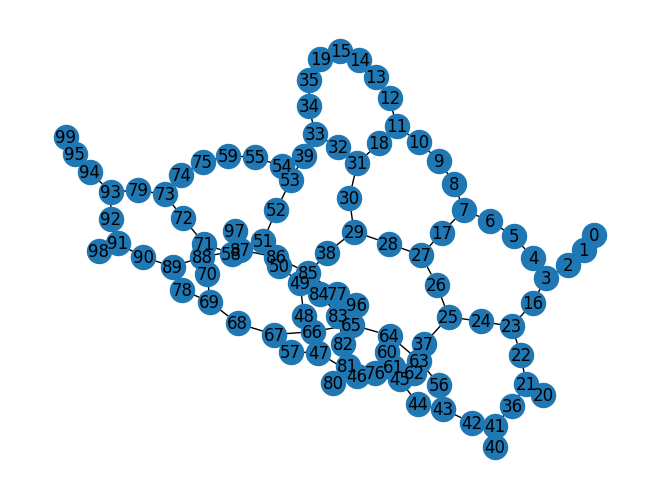

In [3]:
n = 100 
graph = rx.PyGraph()
graph.add_nodes_from((np.arange(0,n,1)))
w = 1.0
elist = []
for edge in backend.coupling_map:
    if (edge[0] < n) and (edge[1] < n):
        if (edge[1],edge[0],w,) not in elist:
            elist.append((edge[0], edge[1], w))

graph.add_edges_from(elist)
draw_graph(graph, with_labels=True)
        

In [4]:
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    """Convert the graph to Pauli list.

    This function does the inverse of `build_max_cut_graph`
    """
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list
        

In [5]:
max_cut_paulis = build_max_cut_paulis(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZ', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZI', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIIIIII', 'IIIIIIIIIIIIIIIIIIIII

In [8]:
# Extract longest path with no repeated nodes
nodes = rx.longest_simple_path(graph)

# Collect even edges and odd edges
even_edges = [
    (nodes[i], nodes[i + 1])
    if nodes[i] < nodes[i + 1]
    else (nodes[i + 1], nodes[i])
    for i in range(0, len(nodes) - 1, 2)
]
odd_edges = [
    (nodes[i], nodes[i + 1])
    if nodes[i] < nodes[i + 1]
    else (nodes[i + 1], nodes[i])
    for i in range(1, len(nodes) - 1, 2)
]
edge_list = [
    (edge[0], edge[1]) if edge[0] < edge[1] else (edge[1], edge[0])
    for edge in graph.edge_list()
]

swap_strategy = SwapStrategy(CouplingMap(edge_list), (even_edges, odd_edges))

In [9]:
"""A class to solve the SWAP gate insertion initial mapping problem
using the SAT approach from https://arxiv.org/abs/2212.05666.
"""


@dataclass
class SATResult:
    """A data class to hold the result of a SAT solver."""

    satisfiable: bool  # Satisfiable is True if the SAT model could be solved
    # in a given time.
    solution: dict  # The solution to the SAT problem if it is satisfiable.
    mapping: list  # The mapping of nodes in the pattern graph to nodes in the
    # target graph.
    elapsed_time: float  # The time it took to solve the SAT model.


class SATMapper:
    r"""A class to introduce a SAT-approach to solve
    the initial mapping problem in SWAP gate insertion for commuting gates.

    When this pass is run on a DAG it will look for the first instance of
    :class:`.Commuting2qBlock` and use the program graph :math:`P` of this block
    of gates to find a layout for a given swap strategy. This layout is found
    with a binary search over the layers :math:`l` of the swap strategy. At each
    considered layer a subgraph isomorphism problem formulated as a SAT is solved
    by a SAT solver. Each instance is whether it is possible to embed the program
    graph :math:`P` into the effective connectivity graph :math:`C_l` that is
    achieved by applying :math:`l` layers of the swap strategy to the coupling map
    :math:`C_0` of the backend. Since solving SAT problems can be hard, a
    ``time_out`` fixes the maximum time allotted to the SAT solver for each
    instance. If this time is exceeded the considered problem is deemed
    unsatisfiable and the binary search proceeds to the next number of swap
    layers :math:``l``.
    """

    def __init__(self, timeout: int = 60):
        """Initialize the SATMapping.

        Args:
            timeout: The allowed time in seconds for each iteration of the SAT
                solver. This variable defaults to 60 seconds.
        """
        self.timeout = timeout

    def find_initial_mappings(
        self,
        program_graph: rx.Graph,
        swap_strategy: SwapStrategy,
        min_layers: int | None = None,
        max_layers: int | None = None,
    ) -> dict[int, SATResult]:
        r"""Find an initial mapping for a given swap strategy. Perform a
        binary search over the number of swap layers, and for each number
        of swap layers solve a subgraph isomorphism problem formulated as
        a SAT problem.

        Args:
            program_graph (rx.Graph): The program graph with commuting gates, where
                                        each edge represents a two-qubit gate.
            swap_strategy (SwapStrategy): The swap strategy to use to find the
                                        initial mapping.
            min_layers (int): The minimum number of swap layers to consider.
                                        Defaults to the maximum degree of the
                                        program graph - 2.
            max_layers (int): The maximum number of swap layers to consider.
                                        Defaults to the number of qubits in the
                                        swap strategy - 2.

        Returns:
            dict[int, SATResult]: A dictionary containing the results of the SAT
                                    solver for each number of swap layers.
        """
        num_nodes_g1 = len(program_graph.nodes())
        num_nodes_g2 = swap_strategy.distance_matrix.shape[0]
        if num_nodes_g1 > num_nodes_g2:
            return SATResult(False, [], [], 0)
        if min_layers is None:
            # use the maximum degree of the program graph - 2
            # as the lower bound.
            min_layers = max((d for _, d in program_graph.degree)) - 2
        if max_layers is None:
            max_layers = num_nodes_g2 - 1

        variable_pool = IDPool(start_from=1)
        variables = np.array(
            [
                [variable_pool.id(f"v_{i}_{j}") for j in range(num_nodes_g2)]
                for i in range(num_nodes_g1)
            ],
            dtype=int,
        )
        vid2mapping = {v: idx for idx, v in np.ndenumerate(variables)}
        binary_search_results = {}

        def interrupt(solver):
            # This function is called to interrupt the solver when the
            # timeout is reached.
            solver.interrupt()

        # Make a cnf (conjunctive normal form) for the one-to-one
        # mapping constraint
        cnf1 = []
        for i in range(num_nodes_g1):
            clause = variables[i, :].tolist()
            cnf1.append(clause)
            for k, m in combinations(clause, 2):
                cnf1.append([-1 * k, -1 * m])
        for j in range(num_nodes_g2):
            clause = variables[:, j].tolist()
            for k, m in combinations(clause, 2):
                cnf1.append([-1 * k, -1 * m])

        # Perform a binary search over the number of swap layers to find the
        # minimum number of swap layers that satisfies the subgraph isomorphism
        # problem.
        while min_layers < max_layers:
            num_layers = (min_layers + max_layers) // 2

            # Create the connectivity matrix. Note that if the swap strategy
            # cannot reach full connectivity then its distance matrix will have
            # entries with -1. These entries must be treated as False.
            d_matrix = swap_strategy.distance_matrix
            connectivity_matrix = (
                (-1 < d_matrix) & (d_matrix <= num_layers)
            ).astype(int)
            # Make a cnf for the adjacency constraint
            cnf2 = []
            for e_0, e_1 in list(program_graph.edge_list()):
                clause_matrix = np.multiply(
                    connectivity_matrix, variables[e_1, :]
                )
                clause = np.concatenate(
                    (
                        [[-variables[e_0, i]] for i in range(num_nodes_g2)],
                        clause_matrix,
                    ),
                    axis=1,
                )
                # Remove 0s from each clause
                cnf2.extend([c[c != 0].tolist() for c in clause])

            cnf = CNF(from_clauses=cnf1 + cnf2)

            with Solver(bootstrap_with=cnf, use_timer=True) as solver:
                # Solve the SAT problem with a timeout.
                # Timer is used to interrupt the solver when the
                # timeout is reached.
                timer = Timer(self.timeout, interrupt, [solver])
                timer.start()
                status = solver.solve_limited(expect_interrupt=True)
                timer.cancel()
                # Get the solution and the elapsed time.
                sol = solver.get_model()
                e_time = solver.time()

                print(
                    f"Layers: {num_layers}, Status: {status}, Time: {e_time}"
                )
                if status:
                    # If the SAT problem is satisfiable, convert the solution
                    # to a mapping.
                    mapping = [vid2mapping[idx] for idx in sol if idx > 0]
                    binary_search_results[num_layers] = SATResult(
                        status, sol, mapping, e_time
                    )
                    max_layers = num_layers
                else:
                    # If the SAT problem is unsatisfiable, return the last
                    # satisfiable solution.
                    binary_search_results[num_layers] = SATResult(
                        status, sol, [], e_time
                    )
                    min_layers = num_layers + 1

        return binary_search_results

    def remap_graph_with_sat(
        self, graph: rx.Graph, swap_strategy, max_layers
    ):
        """Applies the SAT mapping.

        Args:
            graph (nx.Graph): The graph to remap.
            swap_strategy (SwapStrategy): The swap strategy to use
                                            to find the initial mapping.

        Returns:
            tuple: A tuple containing the remapped graph, the edge map, and the
            number of layers of the swap strategy that was used to find the
            initial mapping. If no solution is found then the tuple contains
            None for each element. Note the returned edge map `{k: v}` means that
            node `k` in the original graph gets mapped to node `v` in the
            Pauli strings.
        """
        num_nodes = len(graph.nodes())
        results = self.find_initial_mappings(
            graph, swap_strategy, 0, max_layers
        )
        solutions = [k for k, v in results.items() if v.satisfiable]

        if len(solutions):
            min_k = min(solutions)
            edge_map = dict(results[min_k].mapping)
            # Create the remapped graph
            remapped_graph = rx.PyGraph()
            remapped_graph.add_nodes_from(range(num_nodes))
            mapping = dict(results[min_k].mapping)
            for i, graph_edge in enumerate(list(graph.edge_list())):
                remapped_edge = tuple(mapping[node] for node in graph_edge)
                remapped_graph.add_edge(*remapped_edge, graph.edges()[i])
            return remapped_graph, edge_map, min_k
        else:
            return None, None, None

Layers: 1, Status: True, Time: 0.6799472739999999
Layers: 0, Status: True, Time: 0.041774304000000484
Map from old to new nodes:  {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14, 15: 15, 16: 16, 17: 17, 18: 18, 19: 19, 20: 20, 21: 21, 22: 22, 23: 23, 24: 24, 25: 25, 26: 26, 27: 27, 28: 28, 29: 29, 30: 30, 31: 31, 32: 32, 33: 33, 34: 34, 35: 35, 36: 36, 37: 37, 38: 38, 39: 39, 40: 40, 41: 41, 42: 42, 43: 43, 44: 44, 45: 45, 46: 46, 47: 47, 48: 48, 49: 49, 50: 50, 51: 51, 52: 52, 53: 53, 54: 54, 55: 55, 56: 56, 57: 57, 58: 58, 59: 59, 60: 60, 61: 61, 62: 62, 63: 63, 64: 64, 65: 65, 66: 66, 67: 67, 68: 68, 69: 69, 70: 70, 71: 71, 72: 72, 73: 73, 74: 74, 75: 75, 76: 76, 77: 77, 78: 78, 79: 79, 80: 80, 81: 81, 82: 82, 83: 83, 84: 84, 85: 85, 86: 86, 87: 87, 88: 88, 89: 89, 90: 90, 91: 91, 92: 92, 93: 93, 94: 94, 95: 95, 96: 96, 97: 97, 98: 98, 99: 99}
Min SWAP layers: 0


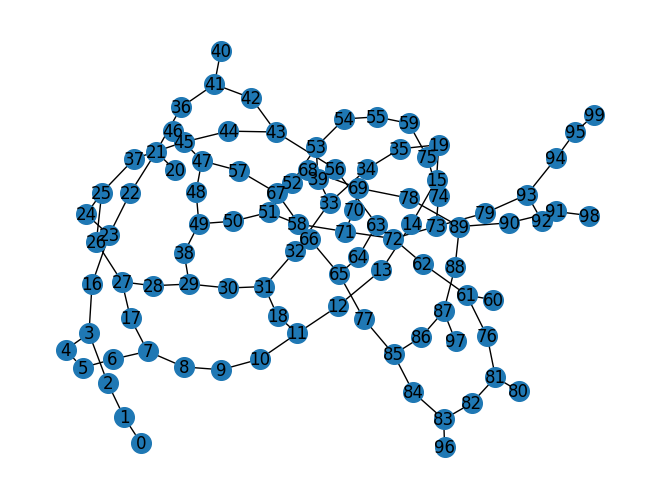

In [12]:
sm = SATMapper(timeout=10)
remapped_graph, edge_map, min_swap_layers = sm.remap_graph_with_sat(
    graph=graph, swap_strategy=swap_strategy, max_layers=2
)
print("Map from old to new nodes: ", edge_map)
print("Min SWAP layers:", min_swap_layers)
draw_graph(remapped_graph, node_size=200, with_labels=True, width=1)

In [13]:
remapped_max_cut_paulis = build_max_cut_paulis(remapped_graph)
# define a qiskit SparsePauliOp from the list of paulis
remapped_cost_operator = SparsePauliOp.from_list(remapped_max_cut_paulis)
print(remapped_cost_operator)

SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZ', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZI', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIZZIIIIIII', 'IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII

In [ ]:
def make_meas_map(circuit: QuantumCircuit) -> dict:
    """Return a mapping from qubit index (the key) to classical bit (the value).

    This allows us to account for the swapping order introduced by the
    SWAP strategy.
    """
    creg = circuit.cregs[0]
    qreg = circuit.qregs[0]

    meas_map = {}
    for inst in circuit.data:
        if inst.operation.name == "measure":
            meas_map[qreg.index(inst.qubits[0])] = creg.index(inst.clbits[0])

    return meas_map


In [ ]:
def apply_swap_strategy(
    circuit: QuantumCircuit,
    swap_strategy: SwapStrategy,
    edge_coloring: dict[tuple[int, int], int] | None = None,
) -> QuantumCircuit:
    """Transpile with a SWAP strategy.

    Returns:
        A quantum circuit transpiled with the given swap strategy.
    """

    pm_pre = PassManager(
        [
            FindCommutingPauliEvolutions(),
            Commuting2qGateRouter(
                swap_strategy,
                edge_coloring,
            ),
        ]
    )
    return pm_pre.run(circuit)

In [ ]:

def apply_qaoa_layers(
    cost_layer: QuantumCircuit,
    meas_map: dict,
    num_layers: int,
    gamma: list[float] | ParameterVector = None,
    beta: list[float] | ParameterVector = None,
    initial_state: QuantumCircuit = None,
    mixer: QuantumCircuit = None,
):
    """Applies QAOA layers to construct circuit.

    First, the initial state is applied. If `initial_state` is None, we begin in
    the initial superposition state. Next, we alternate between layers of the
    cost operator and the mixer. The cost operator is alternatively applied in
    order and in reverse instruction order. This allows us to apply the swap
    strategy on odd `p` layers and undo the swap strategy on even `p` layers.
    """

    num_qubits = cost_layer.num_qubits
    new_circuit = QuantumCircuit(num_qubits, num_qubits)

    if initial_state is not None:
        new_circuit.append(initial_state, range(num_qubits))
    else:
        # all h state by default
        new_circuit.h(range(num_qubits))

    if gamma is None or beta is None:
        gamma = ParameterVector("γ'", num_layers)
        if mixer is None or mixer.num_parameters == 0:
            beta = ParameterVector("β'", num_layers)
        else:
            beta = ParameterVector("β'", num_layers * mixer.num_parameters)

    if mixer is not None:
        mixer_layer = mixer
    else:
        mixer_layer = QuantumCircuit(num_qubits)
        mixer_layer.rx(-2 * beta[0], range(num_qubits))

    for layer in range(num_layers):
        bind_dict = {cost_layer.parameters[0]: gamma[layer]}
        cost_layer_ = cost_layer.assign_parameters(bind_dict)
        bind_dict = {
            mixer_layer.parameters[i]: beta[layer + i]
            for i in range(mixer_layer.num_parameters)
        }
        layer_mixer = mixer_layer.assign_parameters(bind_dict)

        if layer % 2 == 0:
            new_circuit.append(cost_layer_, range(num_qubits))
        else:
            new_circuit.append(cost_layer_.reverse_ops(), range(num_qubits))

        new_circuit.append(layer_mixer, range(num_qubits))

    for qidx, cidx in meas_map.items():
        new_circuit.measure(qidx, cidx)

    return new_circuit